# 2D Kelvin-Helmholtz instability

The `Kelvin-Helmholtz` problem (double shear layer on a periodic 2 x 2 box) at 128²,
run through `luna.launch` like `python main.py`. The command-line equivalent is

```bash
python main.py my_run.py test_problem=Kelvin-Helmholtz SPATIAL_DIMENSION=2 BOUNDARY=0 \
    Nx=128 Ny=128 Lx=2 Ly=2 LIMITER=1 t_end=3
```

This is a demonstration at low resolution, not a validation; the asserted KH tests are
listed in `docs/CLAIMS.md`. The simulation takes about half a minute on a CPU (34 s on four cores, as recorded below).

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

from dataclasses import replace
import matplotlib.pyplot as plt
from luna import Config, launch

In [2]:
cfg = replace(Config(),
              test_problem="Kelvin-Helmholtz", SPATIAL_DIMENSION=2, BOUNDARY=0,
              Nx=128, Ny=128, Lx=2.0, Ly=2.0, LIMITER=1, t_end=3.0,
              time_bet_snaps=1.0, PLOT_AFTER_SIM=False, output_cadence=1000, diag_interval=1000,
              output_dir="snapshots/nb_kh", clear_output_dir=True)
res = launch(cfg)
print("t =", res.t, " steps =", res.n_steps, " output:", res.output_dir)

MULTI-NODE SHARDING MODE (1 GPU per process)
  Running in single-process mode (use SLURM/MPI for multi-node)


Platform: cpu
Total devices: 1
Local devices: 1
  Device 0: cpu (process 0)



DOMAIN DECOMPOSITION (1 devices)
Decomposition strategy: auto
Process grid: (1, 1)
Actual decomposition: slab (1D)

INITIAL CONDITIONS
Single-process mode: generating global initial conditions...


Global shape: (4, 128, 128)
Validating initial conditions...


✓ Initial conditions validated successfully

Sharding global array to all devices...
✓ Array sharded across 1 devices
  Each process keeps only its local shard

After initialization: Memory usage: 0.28 GB

Using shard_map with explicit per-shard ppermute halos
Sharding spec: P(None, 'x', 'y')
Using MUSCL-Hancock (HLLC, shard_map) time integration
Runner controls dt clamping (snapshot times, t_end)


✓ Compilation complete (2.2s)



... (7 outputs left out)

📊 step=   2000  t=2.61518e+00  min_rho=9.605e-01  min_P=8.116e+00  max_|v|=1.750e+00  max_M=4.430e-01  ETA=0.1m
Step  2000, t=2.61518e+00, dt = 1.23310e-03, perf = 1.56 Mcells/s, mem = 0.37 GB



────────────────────────────────────────────────────────────
💾 Saving snapshot #3 at t=3.00000e+00
────────────────────────────────────────────────────────────
Process 0 shard 0: saved snap_003.0.hdf5
✓ snapshot written



[gas] done: 2305 steps, t=3.00000e+00, 34.3s



SIMULATION COMPLETED
✓ Total runtime: 34.31 seconds
✓ Total steps: 2305
✓ Final time: 3.00000
✓ Average performance: 1.10 Mcells/s (global grid)
✓ Time per step: 14.89 ms (excluding first step)

Number of devices: 1
Process grid: (1, 1)

Final memory usage: Memory usage: 0.37 GB

Good Bye and Good Day!
t = 3.0  steps = 2305  output: snapshots/nb_kh


Snapshots are HDF5 directories `snapdir_NNN/` in `output_dir`;
`luna.file_io.read_snapshot` stitches the shards of a multi-device run.

mass drift: 0.0


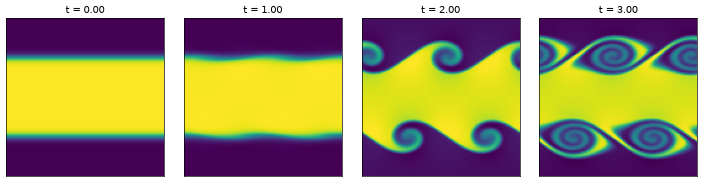

In [3]:
import glob
from luna.file_io.read_snapshot import read_snapshot

snaps = [read_snapshot(d) for d in sorted(glob.glob(f"{cfg.output_dir}/snapdir_*"))]
fig, ax = plt.subplots(1, len(snaps), figsize=(3 * len(snaps), 3), dpi=60)
for a, s in zip(ax, snaps):
    a.imshow(s["rho"].T, origin="lower", extent=(0, s["Lx"], 0, s["Ly"]), cmap="viridis")
    a.set_title(f"t = {s['t']:.2f}"); a.set_xticks([]); a.set_yticks([])
fig.tight_layout()
print("mass drift:", abs(snaps[-1]["rho"].sum() / snaps[0]["rho"].sum() - 1.0))